# BASELINE MODEL

Sprint 2 - Step 2

- Input: the feature dataset from `02_feature_engineering.ipynb` (`data_cleaned/train_features.csv`).
- Model: Logistic Regression, a simple and interpretable baseline.
- Two separate models: one for `h1n1_vaccine` and one for `seasonal_vaccine`.
- Main metric: ROC AUC. The project score is the average ROC AUC of both targets.

## Load the feature dataset

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

CLEAN_DIR = Path("../data_cleaned")

RANDOM_STATE = 42

features_df = pd.read_csv(
    CLEAN_DIR / "train_features.csv"
)

print("Feature dataset:", features_df.shape)

Feature dataset: (26707, 119)


## Separating features and targets

In [2]:
target_columns = [
    "h1n1_vaccine",
    "seasonal_vaccine"
]

target_names = {
    "h1n1_vaccine": "H1N1",
    "seasonal_vaccine": "Seasonal"
}

X = features_df.drop(
    columns=["respondent_id"] + target_columns
)

y = features_df[target_columns]

print("X:", X.shape)
print("y:", y.shape)

X: (26707, 116)
y: (26707, 2)


### Checking the balance of the targets

In [3]:
y.mean().mul(100).round(1).rename(target_names)

H1N1        21.2
Seasonal    46.6
dtype: float64

### Learning from the target balance

- Only about 21% of respondents got the H1N1 vaccine, so this target is imbalanced.
- The seasonal vaccine is almost balanced (about 47%).
- This is why ROC AUC is used instead of accuracy: a model that always says "no" would already be 79% accurate for H1N1.

## Train / validation split

- 80% of the data is used to train the models, 20% is kept aside to test them.
- `stratify` keeps the same share of vaccinated people in both parts.

In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Validation:", X_valid.shape)

Train: (21365, 116)
Validation: (5342, 116)


## Building the model pipeline

- `StandardScaler` puts all features on the same scale, which Logistic Regression needs.
- The pipeline makes sure the scaler only learns from the training data.

In [5]:
def build_baseline_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ])

## Step 1: Cross-validation on the training data

- The training data is split into 5 parts. The model is trained 5 times, each time tested on a different part.
- This gives a more reliable ROC AUC than a single split.

In [6]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = {}

for target in target_columns:
    scores = cross_val_score(
        build_baseline_model(),
        X_train,
        y_train[target],
        cv=cv,
        scoring="roc_auc"
    )

    cv_results[target_names[target]] = scores

cv_summary = pd.DataFrame({
    "mean_roc_auc": {name: scores.mean() for name, scores in cv_results.items()},
    "std_roc_auc": {name: scores.std() for name, scores in cv_results.items()}
})

display(cv_summary.round(4))

print(
    "Average ROC AUC (project score):",
    round(cv_summary["mean_roc_auc"].mean(), 4)
)

,mean_roc_auc,std_roc_auc
H1N1,0.8603,0.0030
Seasonal,0.8551,0.0037


Average ROC AUC (project score): 0.8577


### Learning from cross-validation

- H1N1: mean ROC AUC 0.860, Seasonal: 0.855.
- The scores barely change between the 5 folds (std < 0.004), so the result is stable.
- Average ROC AUC (project score): **0.858**.

## Step 2: Training the final models

- One model per target, trained on the full training part.

In [7]:
models = {}

for target in target_columns:
    model = build_baseline_model()
    model.fit(X_train, y_train[target])

    models[target] = model

print("Trained models:", list(models))

Trained models: ['h1n1_vaccine', 'seasonal_vaccine']


## Step 3: Evaluating on the validation data

In [8]:
results = {}

for target, model in models.items():
    probabilities = model.predict_proba(X_valid)[:, 1]
    predictions = model.predict(X_valid)

    results[target_names[target]] = {
        "roc_auc": roc_auc_score(y_valid[target], probabilities),
        "accuracy": accuracy_score(y_valid[target], predictions),
        "precision": precision_score(y_valid[target], predictions),
        "recall": recall_score(y_valid[target], predictions),
        "f1": f1_score(y_valid[target], predictions)
    }

results_df = pd.DataFrame(results).T

display(results_df.round(4))

print(
    "Average ROC AUC (project score):",
    round(results_df["roc_auc"].mean(), 4)
)

,roc_auc,accuracy,precision,recall,f1
H1N1,0.8661,0.8486,0.7027,0.4978,0.5828
Seasonal,0.8567,0.7823,0.7734,0.7532,0.7632


Average ROC AUC (project score): 0.8614


### Learning from the validation results

- The validation ROC AUC (average 0.861) is close to the cross-validation result, so the model is not overfitting.
- **Seasonal:** precision and recall are balanced (0.77 / 0.75).
- **H1N1:** precision is good (0.70), but recall is only 0.50. The model finds only half of the vaccinated people.
- This is caused by the imbalance (only 21% vaccinated). Accuracy (0.85) looks high but is misleading for this target.

### ROC curves

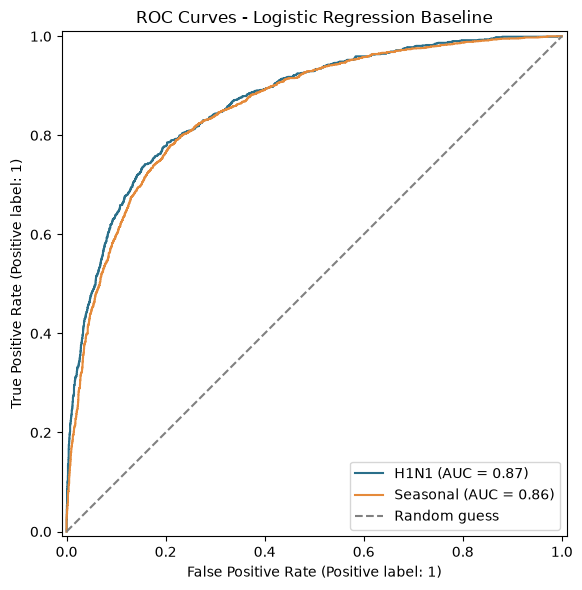

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

colors = {
    "h1n1_vaccine": "#2A6F8A",
    "seasonal_vaccine": "#E58A3A"
}

for target, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_valid,
        y_valid[target],
        name=target_names[target],
        curve_kwargs={"color": colors[target]},
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")

plt.title("ROC Curves - Logistic Regression Baseline")
plt.legend()
plt.tight_layout()
plt.show()

### Confusion matrices

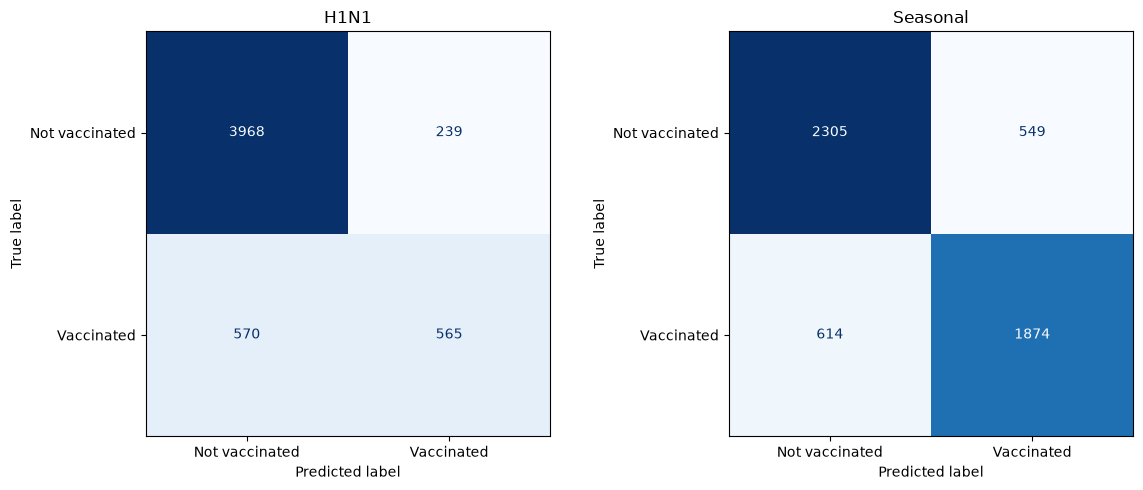

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (target, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_valid,
        y_valid[target],
        display_labels=["Not vaccinated", "Vaccinated"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(target_names[target])

plt.tight_layout()
plt.show()

### Learning from the confusion matrices

- For H1N1 the most common mistake is predicting "not vaccinated" for people who were vaccinated.
- Moving the decision threshold below 0.5 or using `class_weight="balanced"` could raise recall. This can be tested during tuning.

## Step 4: Which features matter most?

- Because the features are scaled, the size of each coefficient shows how strongly it pushes the prediction.
- Positive = more likely to be vaccinated, negative = less likely.

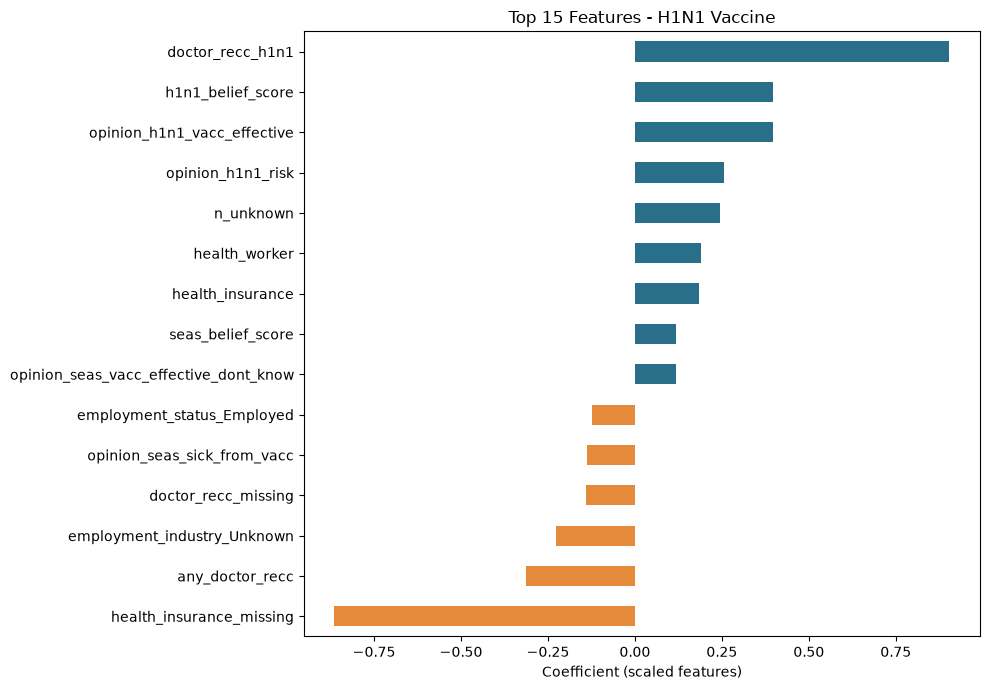

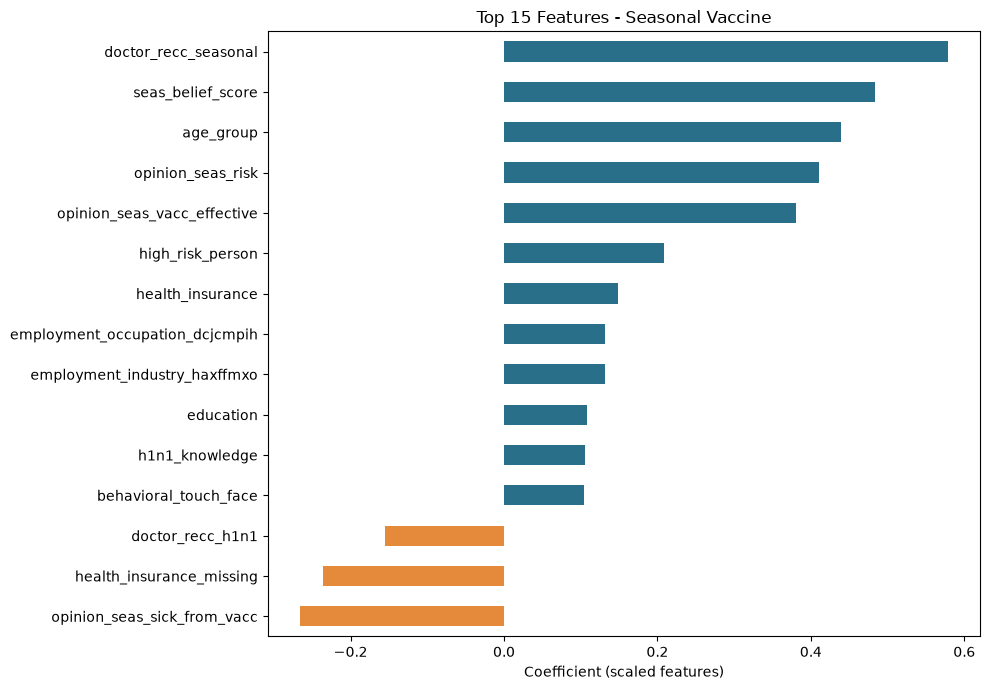

In [11]:
for target, model in models.items():
    coefficients = pd.Series(
        model.named_steps["model"].coef_[0],
        index=X.columns
    )

    top_features = (
        coefficients
        .reindex(coefficients.abs().sort_values(ascending=False).index)
        .head(15)
        .sort_values()
    )

    ax = top_features.plot(
        kind="barh",
        figsize=(10, 7),
        color=[
            "#2A6F8A" if value > 0 else "#E58A3A"
            for value in top_features
        ]
    )

    plt.title(f"Top 15 Features - {target_names[target]} Vaccine")
    plt.xlabel("Coefficient (scaled features)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

### Learning from the feature importance

- **H1N1:** the strongest positive feature is `doctor_recc_h1n1`, followed by `h1n1_belief_score` and the opinion questions. `health_insurance_missing` is strongly negative.
- **Seasonal:** `doctor_recc_seasonal`, `seas_belief_score`, `age_group` and perceived risk are the strongest positive features.
- This confirms the EDA: doctor recommendations (H3), beliefs (H4), age (H1, seasonal only) and insurance (H2) matter most.
- **Careful:** some features are strongly related to each other (e.g. `any_doctor_recc` and `doctor_recc_h1n1`). Their coefficients share the effect and can even get opposite signs, so single coefficients should not be over-interpreted.

# SUMMARY

| Target | CV ROC AUC | Validation ROC AUC |
| --- | --- | --- |
| H1N1 | 0.860 | 0.866 |
| Seasonal | 0.855 | 0.857 |
| **Average (project score)** | **0.858** | **0.861** |

- Logistic Regression gives a strong and stable baseline.
- Next steps: Random Forest and Gradient Boosting, hyperparameter tuning, and comparing them with this baseline.